# Retrospective patch 16.19 matchups — Global and NA Master+

**Repaired and tested with limited live diagnostics on 2026-10-20. Full collection has not been started. Run All starts/resumes the separate repaired run below.** Global Master+ is primary; NA Master+ is the sensitivity benchmark. Both use patch 16.19 and Ranked Solo/Duo; Global includes NA.

Verified champion/lane pages provide named Qwik matchup tables. Fizz → Ahri mid was extracted in both regions: Global 52.41% / 685 matchup games; NA 54.55% / 66 games. These are matchup rows, separate from overall champion statistics. Each page must independently verify filters and returned dataset identity. No sample cutoff, rate imputation, reverse-rate inference, or regional substitution is used.

`queue=ranked` caused the original 404s and is now omitted from website URLs; the returned page must still confirm Ranked Solo/Duo and dataset queue 420. The old run `20261020T163330214361Z` is preserved. The Global directional endpoint disagreed with its champion table, and NA directional Fizz–Ahri returned 404: evidence is retained under `data/lolalytics/diagnostics/20261020_url_repair/`. Directional fallback is disabled by default to keep this run's representation consistent. Do not interpret 404s as missing matchup data.

These are retrospectively collected, overlapping benchmarks and were not necessarily available before target kickoff. Candidate eligibility does not establish champion-select availability.


## 1. Dependencies, configuration and safe resume

Dependencies: `pandas pyarrow requests beautifulsoup4 matplotlib` and Jupyter/IPython. Nothing is installed automatically. Open from the repository root or `hlr_model/`.

The explicit repaired `RUN_ID` below resumes its pinned inputs, plan, cached bodies and checkpoints. The old zero-rate run has incompatible URLs/candidates and must not be resumed with this helper. It has not been overwritten or migrated. To create another run, set `RUN_ID=None, FRESH_RUN=True` once, then restore `FRESH_RUN=False` for resume. An ordinary Run All uses the prepared repaired run.

All original filter, time, hash, region and source-body provenance checks remain required. Parse failures reprocess cached source. URL changes naturally use distinct cache identities. A deliberate same-URL 404 retry is available as `PageCache.get(url, retry_cached_error=True)`; it archives the prior receipt and preserves the prior body and event. Never delete all caches or the old run.


In [13]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LogNorm
from IPython.display import display, Markdown

start = Path.cwd().resolve()
ROOT = next((p for p in [start, *start.parents]
             if (p / 'hlr_model/longitudinal_pipeline.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the repository root or hlr_model/.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
# Fully qualified import avoids accidentally loading the V1 module of the same name.
import importlib
import hlr_model.lolalytics_matchup_scraper as scraper
importlib.reload(scraper)  # Pick up the repair even in an existing notebook kernel.
Config, prepare_collection, collect = scraper.Config, scraper.prepare_collection, scraper.collect
retry_unresolved_pages = scraper.retry_unresolved_pages

RUN_ID = '20261020T164500_repaired'
FRESH_RUN = False  # Preserve and resume all completed Global/NA keys.
# Normal Run All: leave at 0. A positive value runs ONLY a bounded failed-page retry.
RETRY_UNRESOLVED_MAX_PAGES = 0
RETRY_UNRESOLVED_REGIONS = ('na',)
CONFIG = Config(
    patch='16.19', rank='master_plus', regions=('global', 'na'), queue='ranked',
    delay_seconds=2.0, max_attempts=3, timeout_connect=10, timeout_read=45,
    backoff_seconds=5, max_retry_after_seconds=300, max_consecutive_failures=5,
    export_every_pages=20, inspect_batch_tables=True, directional_fallback=False,
    include_current_pick_in_candidates=False,
    candidate_roles=('top', 'jungle', 'mid', 'adc', 'support'),
)

## 2. Input snapshot and deduplicated collection plan

The first run selects the latest valid saved snapshot under `hlr_model/data/runs/patch_16_19_seed_1619/processed/` and reads the actual Parquet schemas for `longitudinal_modeling`, `historical_matches` and `target_matches`. A resumed run uses its pinned snapshot, even if newer snapshots have since appeared. Invalid newer snapshots are reported. Input hashes and immutable plan hashes prevent accidental blending.

**Observed set:** every unique known-opponent target `(lane, champion, opponent_champion)` key, preserving original IDs/names.

**Candidate set:** at each target kickoff, take preserved initial history plus earlier targets with `end_timestamp < kickoff`, count champions previously played in the **same focal role**, and pair them with this target's known opponent. Every previously played same-role champion qualifies; no minimum-experience screen is applied. The currently selected champion is excluded from the candidate set by default, but always remains in the observed set. With `include_current_pick_in_candidates=True` it may support both sets. The all-role pregame main uses the pipeline's count and smallest-ID tie rule; it is included whenever it has same-role prior play. No future games establish eligibility. Missing-opponent targets remain in the coverage denominator but generate no guessed requests.

The plan aggregates observed/alternative flags per key. The decision-to-request mapping retains player, target, candidate ID/name, pregame main status, prior same-role/all-role counts, and latest prior completion timestamp. No claims are made about draft availability. Role aliases are explicitly `TOP → top → top`, `JUNGLE → jungle → jungle`, `MIDDLE → mid → middle`, `BOTTOM → adc → bottom`, `UTILITY → support → support`.

Champion normalization uses an explicit ID/name/slug registry, including MonkeyKing/Wukong, AurelionSol/Aurelion Sol, Velkoz/Vel'Koz and punctuation aliases. Unknown/inconsistent entries produce `unsupported_mapping`; no slug is guessed. Runtime page identity checks must also confirm mapped champions.

Candidates equal to the known opponent champion are excluded before requests are generated. Unexpected observed mirror targets remain in target decisions and `unexpected_observed_mirrors.csv` for investigation and produce no website request. The base decision/candidate mapping is replicated for each region only after eligibility is computed. The full request identity and final long lookup uniqueness include `(patch, rank, region, queue, lane, champion, opponent_champion)`; IDs and normalized slugs remain in the output. `matchup_key_id` is the nonregional matching key, while `key_id` includes all requested filters including region. Per-target counts below distinguish mapping rows from distinct player/target decisions.

In [14]:
context = prepare_collection(ROOT, CONFIG, run_id=RUN_ID, fresh=FRESH_RUN)
RUN_DIR = context['run_dir']
plan = context['plan']
mapping = context['mapping']
manifest = json.loads((RUN_DIR / 'manifest.json').read_text())
print('Input snapshot:', manifest['snapshot'])
print('Active run:', context['run_id'])
print('Output directory:', RUN_DIR.relative_to(ROOT))
display(plan.groupby(['region', 'lane']).agg(
    unique_keys=('key_id', 'size'), observed_keys=('observed', 'sum'),
    alternative_keys=('alternative', 'sum'), directional_pages=('page_url', 'nunique'),
    batch_pages=('batch_url', 'nunique')))
mapping_summary = mapping.groupby(['region', 'request_kind']).agg(
    decision_key_rows=('key_id', 'size'), players=('puuid', 'nunique'),
    unique_matchup_keys=('key_id', 'nunique'))
mapping_summary['target_decisions'] = mapping.drop_duplicates(
    ['region', 'request_kind', 'puuid', 'match_id']).groupby(['region', 'request_kind']).size()
display(mapping_summary)
print('Each target decision can support many candidate-key rows, replicated once per region.')
display(plan[['region', 'lane', 'champion', 'champion_id', 'champion_slug', 'opponent_champion',
              'opponent_slug', 'observed', 'alternative']].head(10))

Selected longitudinal snapshot: hlr_model/data/runs/patch_16_19_seed_1619/processed/20261018T195205790466Z
  longitudinal_modeling: 7,238 rows x 67 columns
  historical_matches: 29,889 rows x 21 columns
  target_matches: 7,238 rows x 21 columns
Run: 20261020T164500_repaired | artifacts: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/hlr_model/data/lolalytics/runs/20261020T164500_repaired
Configuration: {"backoff_seconds": 5, "candidate_roles": ["top", "jungle", "mid", "adc", "support"], "delay_seconds": 2.0, "directional_fallback": false, "export_every_pages": 20, "include_current_pick_in_candidates": false, "inspect_batch_tables": true, "max_attempts": 3, "max_consecutive_failures": 5, "max_retry_after_seconds": 300, "patch": "16.19", "queue": "ranked", "rank": "master_plus", "region": "global", "regions": ["global", "na"], "timeout_connect": 10, "timeout_read": 45}
global: observed=4,361, alternatives=17,225, both purposes=3,589, region keys=17,997; unique directional U

unique_keys  observed_keys  alternative_keys  \
region lane                                                    
global adc             2346            729              2240   
       jungle          3786            858              3686   
       mid             4302           1107              4073   
       support         2870            690              2812   
       top             4693            977              4414   
na     adc             2346            729              2240   
       jungle          3786            858              3686   
       mid             4302           1107              4073   
       support         2870            690              2812   
       top             4693            977              4414   

                directional_pages  batch_pages  
region lane                                     
global adc                   2346           76  
       jungle                3786           86  
       mid                   4302          115  
       support               2870           83  
       top                   4693          117  
na     adc                   2346           76  
       jungle                3786           86  
       mid                   4302          115  
       support               2870           83  
       top                   4693          117

decision_key_rows  players  unique_matchup_keys  \
region request_kind                                                    
global alternative               76285      183                17225   
       observed                   7234      185                 4361   
na     alternative               76285      183                17225   
       observed                   7234      185                 4361   

                     target_decisions  
region request_kind                    
global alternative               7006  
       observed                  7234  
na     alternative               7006  
       observed                  7234

Each target decision can support many candidate-key rows, replicated once per region.


,region,lane,champion,champion_id,champion_slug,opponent_champion,opponent_slug,observed,alternative
0,global,adc,Xerath,101,xerath,Varus,varus,False,True
1,global,adc,Xerath,101,xerath,Viktor,viktor,False,True
2,global,adc,Xerath,101,xerath,Ziggs,ziggs,False,True
3,global,adc,Xerath,101,xerath,Draven,draven,False,True
4,global,adc,Xerath,101,xerath,Jayce,jayce,False,True
5,global,adc,Xerath,101,xerath,Syndra,syndra,False,True
6,global,adc,Xerath,101,xerath,Kaisa,kaisa,False,True
7,global,adc,Xerath,101,xerath,Seraphine,seraphine,False,True
8,global,adc,Xerath,101,xerath,Sivir,sivir,False,True
9,global,adc,Xerath,101,xerath,Yasuo,yasuo,False,True


## 3. Verified tables, pacing and collection

URLs use explicit `lane` plus `tier=master_plus&patch=16.19`. Global omits region; NA adds `region=na`. The queue query is omitted because `queue=ranked` returned 404 in a controlled comparison. **Returned current navigation controls must confirm region, Master+, patch and Ranked Solo/Duo; the returned dataset header must confirm queue 420, patch, champion and focal lane.** Query strings alone never establish filters. Redirects are recorded and refused.

The reviewed Qwik adapter decodes only uniquely identified named dataset objects. Server-supplied `enemy_h = [id, wr, d1, d2, pr, n]` labels the matchup rows in `enemy[opposing_lane]`. Focal champion/lane identity, counter-table direction, schema, numeric values and matchup counts must all pass checks. Same-role extraction uses only the focal lane's opposing-lane table and only planned opponent IDs. `header.wr` and `header.n` are overall champion statistics and never become matchup statistics. Explicit wins/losses remain missing unless published. Delta 2 stays separate from raw win rate.

An opponent absent from an otherwise verified table is recorded as `not_published_in_table`, with unknown rate/sample; it does not become zero games or 50%. That representation-specific status is terminal for this run. Directional fallback defaults to false because the inspected endpoints disagreed. An isolated HTTP or parsing failure appends `page_unavailable_unresolved` checkpoints for every affected key, retaining the error, source receipt/body and missing statistics, then continues to the next champion/lane page. Normal resume skips those unresolved pages. A 404 never establishes zero games, no matchup data, or a rate. All table pages are verified independently; a low-volume first champion cannot disable batching for the entire region.

Requests are sequential, paced, cached and bounded. Access challenges, HTTP 401/403, persistent 429 and an explicitly unavailable historical patch pause immediately. With `max_consecutive_failures=5`, five consecutive failed pages OR at least five failures within ten regional pages pause for inspection. A successful table resets the consecutive count; regions have separate failure windows. No challenge bypass is used. Interrupted runs retain checkpoints and raw responses. If a hard kill leaves `collector.lock`, remove only that lock after verifying the collector has stopped.

The plan prints both the table request estimate and the much larger optional directional scenario. These assume two seconds response time plus configured pacing; retry/block delays are excluded. Actual network attempts and timings remain separate by region.

**The next cell starts full collection when you run it. No full collection was launched during repair.** Run All again with the same run ID to resume.


**Resume this existing run:** retain `RUN_ID='20261020T164500_repaired'`, `FRESH_RUN=False`, `RETRY_UNRESOLVED_MAX_PAGES=0`, and click Run All. Completed Global pages and completed NA pages are validated and reused; unresolved pages are skipped so pending NA pages can proceed. The cached NA Volibear ADC 404 affects two alternative keys and is recorded separately.

**Explicit retry later:** set `RETRY_UNRESOLVED_MAX_PAGES=5` (allowed 1–100) and `RETRY_UNRESOLVED_REGIONS=('na',)`, then Run All. This mode retries ONLY up to five unresolved NA pages, each with at most `CONFIG.max_attempts` HTTP attempts. It does not collect pending pages or refetch successful pages. Previous receipts are archived before refresh; bodies and checkpoint history stay intact. Restore the limit to `0` to continue normal pending-page collection. Re-running with a positive limit explicitly authorizes another bounded pass.


In [15]:
if RETRY_UNRESOLVED_MAX_PAGES:
    lookup, coverage_summary, quality = retry_unresolved_pages(
        context, max_pages=RETRY_UNRESOLVED_MAX_PAGES,
        regions=RETRY_UNRESOLVED_REGIONS)
else:
    lookup, coverage_summary, quality = collect(context)


Resume: 473 page operations; completed regional pages are reused; directional fallback disabled.
na | pages this pass=1/473 | valid keys=17,721 | unresolved keys=2 | HTTP attempts=1 | cache hits=0
na | pages this pass=2/473 | valid keys=17,766 | unresolved keys=2 | HTTP attempts=2 | cache hits=0
na | pages this pass=3/473 | valid keys=17,818 | unresolved keys=2 | HTTP attempts=3 | cache hits=0
na | pages this pass=4/473 | valid keys=17,866 | unresolved keys=2 | HTTP attempts=4 | cache hits=0
na | pages this pass=5/473 | valid keys=17,917 | unresolved keys=2 | HTTP attempts=5 | cache hits=0
na | pages this pass=6/473 | valid keys=17,918 | unresolved keys=2 | HTTP attempts=6 | cache hits=0
na | pages this pass=7/473 | valid keys=17,968 | unresolved keys=2 | HTTP attempts=7 | cache hits=0
na | pages this pass=8/473 | valid keys=18,000 | unresolved keys=2 | HTTP attempts=8 | cache hits=0
na | pages this pass=9/473 | valid keys=18,002 | unresolved keys=2 | HTTP attempts=9 | cache hits=0
na 

## 4. Coverage, network requests and remaining issues

The long lookup contains every planned key in both regions, including pending, no-data, unsupported and failed rows. Its uniqueness is checked on the full regional key. Regional coverage denominators refer to the same target decisions; missing-opponent targets remain in each region's total denominator. Known opponents lacking statistics remain distinct from unidentified opponents.

`regional_comparison.{parquet,csv}` preserves one row per nonregional matchup, even when either regional rate is unavailable. Raw rates and tier averages/derived rates have explicit Global and NA names. `na_minus_global_pp` is `NA raw percent − Global raw percent`, with no additional factor of 100, and is calculated only when **both** results are valid. Global and NA statuses, errors, source URLs, collection times and filter evidence remain separate.

`page_summary_by_region.csv` separately counts successful verified tables, verified tables missing requested opponents, unresolved failed pages and affected keys, other attempted failures, and pending pages. `page_status.csv` contains one row per planned regional champion/lane URL; `unresolved_pages.csv` lists unresolved pages. `all_planned_pages_attempted` describes collection effort; `all_keys_valid` describes data availability. An attempted page or completed pass does not imply valid rates for every key. Failed-page outcomes are also appended to `page_events.jsonl`.


In [16]:
display(coverage_summary.style.format({'coverage': '{:.1%}'}, na_rep='—'))
display(lookup.groupby(['region', 'status'], dropna=False).size().rename('keys').to_frame())
network = pd.read_csv(RUN_DIR / 'network_summary_by_region.csv')
display(network)
print('Actual total unique network URLs:', quality['actual_unique_network_urls'])
print('Actual total HTTP attempts:', quality['actual_http_attempts'])
print('In-flight attempts without recorded finish:', quality['unfinished_http_attempts'])
print('HTTP time excluding pacing (seconds):', round(quality['actual_request_seconds'], 1))
print('Prior completed session wall time (seconds):', round(quality['recorded_prior_session_seconds'], 1))
print('Current session wall time (seconds):', round(quality['current_session_seconds'], 1))
print('Reused completed legacy Global keys:', quality['reused_legacy_global_keys'])
print('Unidentified lane-opponent target rows:', quality['unidentified_opponent_target_rows'])
for region, stats in quality['by_region'].items():
    print(region, '| successful rates missing region-specific tier average:', stats['successful_rates_missing_tier_average'],
          '| unverified keys (including pending):', stats['unverified_filter_keys'])
print('Target observations with valid BOTH-region rates:', quality['both_regions_target_rows'],
      f"({quality['both_regions_all_target_share']:.1%} of all targets)")
print('Remaining retryable / pending regional keys:', quality['remaining_retryable_keys'])
remaining = lookup.loc[~lookup.status.eq('ok'),
    ['region', 'lane', 'champion', 'opponent_champion', 'status', 'filters_verified', 'error']]
display(remaining.head(20))
print('Full failure/no-data report:', RUN_DIR / 'failure_no_data_report.csv')
page_summary = pd.read_csv(RUN_DIR / 'page_summary_by_region.csv')
display(page_summary)
print('All planned pages attempted:', quality['all_planned_pages_attempted'])
print('All planned keys have valid rates:', quality['all_keys_valid'])
print('Pending keys:', quality['pending_keys'])
print('Unresolved failed-page keys:', quality['unresolved_failed_keys'])
unresolved_pages = pd.read_csv(RUN_DIR / 'unresolved_pages.csv')
display(unresolved_pages)
print('Page-level detail:', RUN_DIR / 'page_status.csv')
print('Successful pages count verified tables, including those missing some requested opponents.')
print('Missing opponents are a subset of verified tables; unresolved pages are a separate category.')


,region,metric,total,covered,coverage
0,global,observed_target_rows_all,7238,7232,99.9%
1,global,observed_known_opponent_rows,7234,7232,100.0%
2,global,observed_unique_keys,4361,4359,100.0%
3,global,alternative_unique_keys,17225,16895,98.1%
4,global,lane_top_observed_all_rows,1339,1338,99.9%
5,global,lane_top_observed_keys,977,976,99.9%
6,global,lane_top_alternative_keys,4414,4362,98.8%
7,global,lane_jungle_observed_all_rows,1287,1287,100.0%
8,global,lane_jungle_observed_keys,858,858,100.0%
9,global,lane_jungle_alternative_keys,3686,3612,98.0%


keys
region status                            
global not_published_in_table         332
       ok                           17665
na     not_published_in_table        1927
       ok                           15949
       page_unavailable_unresolved    121

,region,planned_unique_directional_pages,possible_unique_batch_pages,planned_unique_page_upper_bound,actual_unique_network_urls,actual_http_attempts,unfinished_http_attempts,actual_request_seconds
0,global,17997,477,18474,477,477,0,195.298
1,na,17997,477,18474,477,477,0,178.154


Actual total unique network URLs: 954
Actual total HTTP attempts: 954
In-flight attempts without recorded finish: 0
HTTP time excluding pacing (seconds): 373.5
Prior completed session wall time (seconds): 1166.9
Current session wall time (seconds): 1166.1
Reused completed legacy Global keys: 0
Unidentified lane-opponent target rows: 4
global | successful rates missing region-specific tier average: 0 | unverified keys (including pending): 0
na | successful rates missing region-specific tier average: 0 | unverified keys (including pending): 121
Target observations with valid BOTH-region rates: 7219 (99.7% of all targets)
Remaining retryable / pending regional keys: 121


,region,lane,champion,opponent_champion,status,filters_verified,error
42,global,adc,Fizz,Rengar,not_published_in_table,True,Opponent absent from returned same-role enemy ...
57,global,adc,Volibear,Aphelios,not_published_in_table,True,Opponent absent from returned same-role enemy ...
72,global,adc,Kayle,Nilah,not_published_in_table,True,Opponent absent from returned same-role enemy ...
375,global,adc,Zyra,Annie,not_published_in_table,True,Opponent absent from returned same-role enemy ...
447,global,adc,Seraphine,Annie,not_published_in_table,True,Opponent absent from returned same-role enemy ...
479,global,adc,Seraphine,Malphite,not_published_in_table,True,Opponent absent from returned same-role enemy ...
738,global,adc,Kindred,Taliyah,not_published_in_table,True,Opponent absent from returned same-role enemy ...
744,global,adc,Kindred,Morgana,not_published_in_table,True,Opponent absent from returned same-role enemy ...
751,global,adc,Kindred,Heimerdinger,not_published_in_table,True,Opponent absent from returned same-role enemy ...
754,global,adc,Kindred,KogMaw,not_published_in_table,True,Opponent absent from returned same-role enemy ...


Full failure/no-data report: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/hlr_model/data/lolalytics/runs/20261020T164500_repaired/failure_no_data_report.csv


,region,planned_pages,successful_pages,verified_tables_missing_requested_opponents,missing_requested_opponent_keys,unresolved_failed_pages,unresolved_failed_keys,other_attempted_failed_pages,attempted_pages,pending_pages,valid_keys,all_planned_pages_attempted,all_keys_valid
0,global,477,477,161,332,0,0,0,477,0,17665,True,False
1,na,477,465,397,1927,12,121,0,477,0,15949,True,False


All planned pages attempted: True
All planned keys have valid rates: False
Pending keys: 0
Unresolved failed-page keys: 121


,region,batch_url,page_status,attempted,successful_page,planned_keys,valid_keys,missing_requested_opponent_keys,unresolved_failed_keys,pending_keys,all_keys_valid,http_status,error
0,na,https://lolalytics.com/lol/volibear/build/?lan...,page_unavailable_unresolved,True,False,2,0,0,2,0,False,404,HTTP 404: page unavailable; matchup availabili...
1,na,https://lolalytics.com/lol/amumu/build/?lane=b...,page_unavailable_unresolved,True,False,11,0,0,11,0,False,404,HTTP 404: page unavailable; matchup availabili...
2,na,https://lolalytics.com/lol/ornn/build/?lane=bo...,page_unavailable_unresolved,True,False,4,0,0,4,0,False,404,HTTP 404: page unavailable; matchup availabili...
3,na,https://lolalytics.com/lol/xinzhao/build/?lane...,page_unavailable_unresolved,True,False,22,0,0,22,0,False,404,HTTP 404: page unavailable; matchup availabili...
4,na,https://lolalytics.com/lol/garen/build/?lane=j...,page_unavailable_unresolved,True,False,4,0,0,4,0,False,404,HTTP 404: page unavailable; matchup availabili...
5,na,https://lolalytics.com/lol/hwei/build/?lane=ju...,page_unavailable_unresolved,True,False,17,0,0,17,0,False,404,HTTP 404: page unavailable; matchup availabili...
6,na,https://lolalytics.com/lol/ryze/build/?lane=su...,page_unavailable_unresolved,True,False,19,0,0,19,0,False,404,HTTP 404: page unavailable; matchup availabili...
7,na,https://lolalytics.com/lol/azir/build/?lane=su...,page_unavailable_unresolved,True,False,19,0,0,19,0,False,404,HTTP 404: page unavailable; matchup availabili...
8,na,https://lolalytics.com/lol/vayne/build/?lane=s...,page_unavailable_unresolved,True,False,12,0,0,12,0,False,404,HTTP 404: page unavailable; matchup availabili...
9,na,https://lolalytics.com/lol/rumble/build/?lane=...,page_unavailable_unresolved,True,False,9,0,0,9,0,False,404,HTTP 404: page unavailable; matchup availabili...


Page-level detail: /Users/minhho-hoang/Documents/riot_proj/riot-game-prediction/hlr_model/data/lolalytics/runs/20261020T164500_repaired/page_status.csv
Successful pages count verified tables, including those missing some requested opponents.
Missing opponents are a subset of verified tables; unresolved pages are a separate category.


## 5. Sample sizes and threshold sensitivity

`matchup_games` is the sample for the requested **directional same-role matchup**, not overall champion games. Every positive sample is preserved, including one-game samples. Zero games or unpublished matchups never become 50% rates. No sample threshold filters the saved lookup.

In [17]:
sample_summary = pd.read_csv(RUN_DIR / 'matchup_sample_distribution.csv')
thresholds = pd.read_csv(RUN_DIR / 'sample_threshold_coverage.csv')
display(sample_summary)
rate_columns = ['all_target_row_coverage', 'observed_key_coverage', 'alternative_key_coverage']
display(thresholds.style.format({c: '{:.1%}' for c in rate_columns}, na_rep='—'))
valid = lookup.status.eq('ok') & lookup.filters_verified
if valid.any():
    display(lookup.loc[valid].groupby(['region', 'lane']).agg(
        matchup_keys=('key_id', 'size'), min_games=('matchup_games', 'min'),
        median_games=('matchup_games', 'median'), max_games=('matchup_games', 'max'),
        missing_tier_averages=('tier_average_missing', 'sum')))
else:
    print('No rates accepted. Inspect quality_summary.json, strategy events and cached responses; do not impute rates.')
print('Paired coverage when BOTH regional samples meet a threshold:')
both_thresholds = pd.read_csv(RUN_DIR / 'both_regions_sample_coverage.csv')
display(both_thresholds.style.format({'all_target_share': '{:.1%}'}, na_rep='—'))

,region,statistic,matchup_games
0,global,count,17665.000000
1,global,mean,234.250269
2,global,std,482.997938
3,global,min,1.000000
4,global,10%,7.000000
5,global,25%,22.000000
6,global,50%,81.000000
7,global,75%,250.000000
8,global,90%,572.000000
9,global,95%,938.000000


,region,minimum_matchup_games,lookup_keys,observed_target_rows,all_target_row_coverage,observed_keys,alternative_keys,observed_key_coverage,alternative_key_coverage
0,global,0,17665,7232,99.9%,4359,16895,100.0%,98.1%
1,global,10,15264,6971,96.3%,4106,14699,94.2%,85.3%
2,global,25,12869,6682,92.3%,3839,12477,88.0%,72.4%
3,global,50,10590,6331,87.5%,3532,10355,81.0%,60.1%
4,global,100,8050,5865,81.0%,3135,7944,71.9%,46.1%
5,global,200,5339,5120,70.7%,2559,5294,58.7%,30.7%
6,global,500,2086,3352,46.3%,1405,2081,32.2%,12.1%
7,na,0,15949,7219,99.7%,4346,15190,99.7%,88.2%
8,na,10,8247,6038,83.4%,3256,8104,74.7%,47.0%
9,na,25,4426,4816,66.5%,2334,4390,53.5%,25.5%


matchup_keys  min_games  median_games  max_games  \
region lane                                                        
global adc              2285        1.0          86.0     9278.0   
       jungle           3712        1.0          98.0     4607.0   
       mid              4217        1.0          68.0     3005.0   
       support          2811        1.0          89.0     6042.0   
       top              4640        1.0          71.0     2400.0   
na     adc              2085        1.0          13.0      887.0   
       jungle           3425        1.0          11.0      299.0   
       mid              3763        1.0           9.0      296.0   
       support          2511        1.0          12.0      368.0   
       top              4165        1.0           8.0      180.0   

                missing_tier_averages  
region lane                            
global adc                          0  
       jungle                       0  
       mid                          0  
       support                      0  
       top                          0  
na     adc                          0  
       jungle                       0  
       mid                          0  
       support                      0  
       top                          0

Paired coverage when BOTH regional samples meet a threshold:


,minimum_games_in_each_region,target_rows,all_target_share,observed_unique_keys,alternative_unique_keys
0,0,7219,99.7%,4346,15190
1,10,6038,83.4%,3256,8104
2,25,4816,66.5%,2334,4390
3,50,3329,46.0%,1357,1976
4,100,1842,25.4%,553,645
5,200,794,11.0%,144,149
6,500,157,2.2%,12,12


## 6. Paired regional differences

Unique-key summaries give each requested matchup one vote. The observed-unique-key summary limits this to combinations actually picked. Target-row-weighted summaries repeat rates for every relevant focal player-game, so common matchups receive greater weight. These weighting choices can give different distributions; shared matches and repeated players remain dependent observations. Differences are descriptive and not significance tests. Largest discrepancies are always shown with **both sample sizes**, including tiny samples.

population,all_requested_unique_keys,observed_player_games,observed_unique_keys
statistic,,,
10%,-25.00,-10.88,-14.04
25%,-8.78,-4.37,-5.68
50%,0.00,0.08,0.00
75%,9.85,4.80,6.02
90%,26.15,11.97,15.26
95%,41.92,19.29,24.70
count,15949.00,7219.00,4346.00
max,85.71,75.00,75.00
mean,0.29,0.23,0.21


,lane,champion,opponent_champion,observed,alternative,global_raw_winrate,global_matchup_games,na_raw_winrate,na_matchup_games,na_minus_global_pp
0,adc,Aphelios,Neeko,False,True,88.89%,9,0.00%,1,-88.89
1,mid,Orianna,Volibear,False,True,88.89%,9,0.00%,1,-88.89
2,mid,Orianna,Briar,False,True,88.89%,9,0.00%,1,-88.89
3,mid,Garen,Sion,False,True,14.29%,7,100.00%,1,+85.71
4,top,AurelionSol,Urgot,False,True,14.29%,7,100.00%,1,+85.71
5,jungle,LeeSin,KogMaw,True,True,84.00%,25,0.00%,1,-84.00
6,support,Soraka,Nunu,False,True,83.33%,12,0.00%,2,-83.33
7,top,Lucian,Swain,False,True,83.33%,6,0.00%,1,-83.33
8,jungle,KogMaw,LeeSin,False,True,17.39%,23,100.00%,1,+82.61
9,mid,Diana,Smolder,False,True,80.00%,10,0.00%,1,-80.00


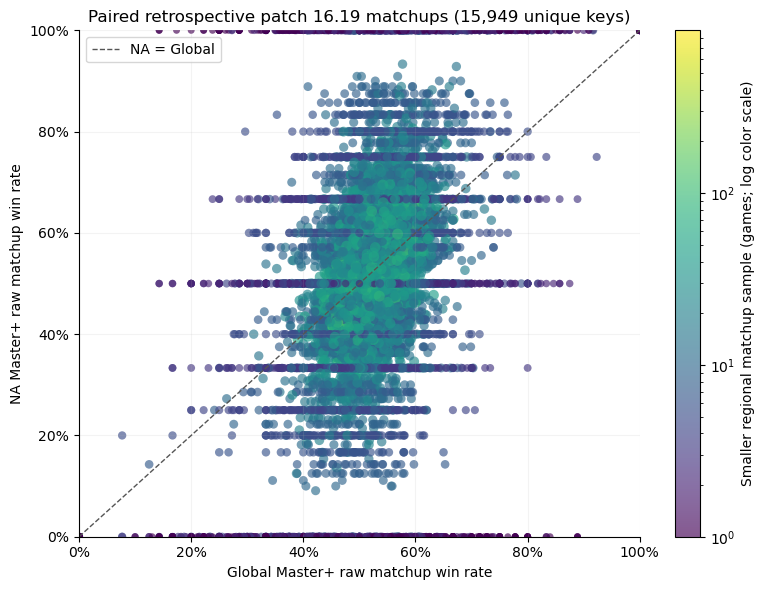

In [18]:
paired = pd.read_parquet(RUN_DIR / 'regional_comparison.parquet')
target_pairs = pd.read_parquet(RUN_DIR / 'paired_target_observations.parquet')
difference_summary = pd.read_csv(RUN_DIR / 'regional_difference_distribution.csv')
display(difference_summary.pivot(index='statistic', columns='population', values='na_minus_global_pp').round(2))
extremes = pd.read_csv(RUN_DIR / 'largest_regional_differences.csv')
display(extremes[['lane', 'champion', 'opponent_champion', 'observed', 'alternative',
    'global_raw_winrate', 'global_matchup_games', 'na_raw_winrate', 'na_matchup_games',
    'na_minus_global_pp']].head(15).style.format({
        'global_raw_winrate': '{:.2f}%', 'na_raw_winrate': '{:.2f}%',
        'na_minus_global_pp': '{:+.2f}', 'global_matchup_games': '{:,.0f}',
        'na_matchup_games': '{:,.0f}'}, na_rep='—'))
plot_data = paired.loc[paired.both_regions_valid].copy()
if not plot_data.empty:
    # Color and size both reflect the smaller of the two regional sample sizes.
    samples = plot_data.smaller_regional_sample
    fig, ax = plt.subplots(figsize=(8, 6))
    points = ax.scatter(plot_data.global_raw_winrate, plot_data.na_raw_winrate,
        c=samples, s=18 + 10*np.log1p(samples), cmap='viridis',
        norm=LogNorm(vmin=1, vmax=max(2, samples.max())), alpha=.65, edgecolors='none')
    ax.plot([0, 100], [0, 100], color='#555555', linestyle='--', linewidth=1, label='NA = Global')
    ax.set(xlim=(0, 100), ylim=(0, 100), xlabel='Global Master+ raw matchup win rate',
        ylabel='NA Master+ raw matchup win rate',
        title=f'Paired retrospective patch 16.19 matchups ({len(plot_data):,} unique keys)')
    ax.xaxis.set_major_formatter(PercentFormatter(100))
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=.15)
    fig.colorbar(points, ax=ax, label='Smaller regional matchup sample (games; log color scale)')
    ax.legend(loc='upper left')
    fig.tight_layout()
    fig.savefig(RUN_DIR / 'na_vs_global_scatter.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('No valid pairs: difference fields remain missing and no scatterplot is generated.')

## 7. Later sensitivity-analysis design — no model fitting here

A. Fit and evaluate the primary model using **Global Master+**, following the prespecified chronological design.

B. On the subset with valid rates in **both** regions, fit/evaluate otherwise identical Global-based and NA-based models using the **same observations, chronological partitions, predictor definitions, preprocessing and tuning procedure**. Keep all player rows from a shared match in one partition. Derive any preprocessing or tuning decisions from training/validation only.

C. Report the change in coverage and composition separately from model changes. First compare the full Global-coverage sample with the common paired subset, then compare benchmarks within that identical paired subset.

D. Compare estimated proficiency/matchup relationships, calibration, Brier score, log loss, ROC-AUC and substantive conclusions. Preserve the repeated-player/shared-match uncertainty limitations; regional populations overlap.

E. Do not choose the benchmark based on final test performance. Global is primary by design; NA is a prespecified sensitivity analysis. Both sources are retrospective patch-16.19 benchmarks, not necessarily statistics available before target games. A time-safe predictive analysis needs separately justified historical availability; sequential feature updates do not make retrospective external rates time-safe.

## 8. Saved artifacts, rate definitions, and interpretation

Everything produced by collection is under `hlr_model/data/lolalytics/runs/<run_id>/`:

- `manifest.json`: pinned snapshot, input/plan hashes, configuration, actual schemas and definitions.
- `request_plan.{parquet,csv}`, `decision_request_mapping.{parquet,csv}`, `target_decisions.{parquet,csv}`: deduplicated scope, original identifiers, normalized website keys, observed/alternative flags and decision-time candidate evidence.
- `responses/`: raw source bodies plus URL-indexed receipts, UTC retrieval times, hashes, statuses and selected diagnostic headers. `request_events.jsonl` records every actual attempt, including retries.
- `matchup_checkpoint.jsonl`: incrementally flushed/fsynced per-key results; `sessions.jsonl`, `run_state.json`, `strategy.json`, `strategy_events.jsonl`, `representation_inventory.jsonl` document runtime and parsing decisions (strategy files appear when a probe occurs).
- `matchup_lookup.{parquet,csv}`: exactly one row per full matchup/region key, including failures and no-data cases; `failure_no_data_report.csv` retains full problems.
- `regional_comparison.{parquet,csv}` and `paired_target_observations.{parquet,csv}`: paired regional values with both-region validity and NA-minus-Global differences; missing regions stay missing.
- `regional_difference_distribution.csv`, `largest_regional_differences.csv`, `both_regions_sample_coverage.csv`, `network_summary_by_region.csv`, and `na_vs_global_scatter.png` (when paired data exist): regional comparisons and sample/request context.
- `coverage_summary.csv`, `sample_threshold_coverage.csv`, `matchup_sample_distribution.csv`, `quality_summary.json`: coverage, sample sizes, missing tier averages, unverified filters, measured attempts and runtime.

All win rates are percentages. This includes paired `global_raw_winrate`, `na_raw_winrate`, the regional tier averages and separately named derived tier-centered rates. `na_minus_global_pp` is in percentage points. All long-format win-rate fields ending `_pct` are also in percentage units. `raw_matchup_winrate_pct` remains the raw website estimate. Explicitly available wins/losses are stored without reconstruction. `tier_average_winrate_pct` requires a labeled **Average Master+ Win Rate** and retains its source/context; missing averages stay missing and flagged. `derived_tier_centered_rate_pct = raw_matchup_winrate_pct − tier_average_winrate_pct + 50` is an explicitly derived tier-centered value, **not a website-provided probability**, and may fall outside 0–100. It is never replaced by the raw rate when the average is absent. `website_delta2_pp` is a separately retained website normalization statistic, with its reported definition/context. No-data and errors retain missing rates.

Returned filter evidence, champion/role evidence, source URL/body hash, run ID, UTC retrieval and parsing times are preserved. These retrospective rates have a different population and time provenance from NA target games. They do not provide a time-safe pregame predictor, establish champion-select availability, or estimate the effect of switching champions. Resolve remaining verification/coverage issues before integrating them into modeling.

Global remains the primary benchmark. Global includes NA, so paired differences compare overlapping populations and do not represent independent estimates. Collection timestamps can also differ between requests. The collection notebook fits no models.
- `page_status.csv`, `page_summary_by_region.csv`, `unresolved_pages.csv`, `page_events.jsonl`: per-region page completion, table omissions, unresolved page failures and bounded retry evidence.
